In [ ]:

import torch
import torchvision
import platform

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available - CPU will be used")


Python Version: 3.13.16
PyTorch Version: 2.11.0+cu130
Torchvision Version: 0.26.0+cu130
GPU Available: Tesla T4


In [ ]:

import os
import urllib.request

DATA_DIR = "/content/AquaClass_AI"
os.makedirs(DATA_DIR, exist_ok=True)

url = "https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/"

print("Project directory created:", DATA_DIR)
print("Dataset source:", url)
print("Ready for dataset download.")


Project directory created: /content/AquaClass_AI
Dataset source: https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/
Ready for dataset download.


In [ ]:

import os
import urllib.request

BASE_URL = "https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/"
DATA_DIR = "/content/AquaClass_AI/dataset"

os.makedirs(DATA_DIR, exist_ok=True)

species = {
    "01": "Dascyllus_reticulatus",
    "02": "Plectroglyphidodon_dickii",
    "03": "Chromis_chrysura",
    "04": "Amphiprion_clarkii",
    "05": "Chaetodon_lunulatus"
}

print("Selected species:")
for code, name in species.items():
    print(code, name)

print("\nDataset directory:", DATA_DIR)
print("Ready for archive download.")


Selected species:
01 Dascyllus_reticulatus
02 Plectroglyphidodon_dickii
03 Chromis_chrysura
04 Amphiprion_clarkii
05 Chaetodon_lunulatus

Dataset directory: /content/AquaClass_AI/dataset
Ready for archive download.


In [ ]:

import os
import tarfile
import urllib.request

BASE_URL = "https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/Archive/fish_image/"

DATA_DIR = "/content/AquaClass_AI/dataset"
os.makedirs(DATA_DIR, exist_ok=True)

species = {
    "fish_01.tar": "Dascyllus_reticulatus",
    "fish_02.tar": "Plectroglyphidodon_dickii",
    "fish_03.tar": "Chromis_chrysura",
    "fish_04.tar": "Amphiprion_clarkii",
    "fish_05.tar": "Chaetodon_lunulatus"
}

for archive, class_name in species.items():

    class_dir = os.path.join(DATA_DIR, class_name)
    os.makedirs(class_dir, exist_ok=True)

    archive_path = os.path.join("/content", archive)
    download_url = BASE_URL + archive

    print(f"\nDownloading: {class_name}")

    urllib.request.urlretrieve(download_url, archive_path)

    print("Download complete. Extracting...")

    with tarfile.open(archive_path, "r") as tar:
        tar.extractall(path=class_dir)

    os.remove(archive_path)

    print(f"Extracted: {class_name}")

print("\nAll 5 species downloaded and extracted!")



Downloading: Dascyllus_reticulatus
Download complete. Extracting...


/tmp/ipykernel_783/2491039629.py:33: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=class_dir)


Extracted: Dascyllus_reticulatus

Downloading: Plectroglyphidodon_dickii
Download complete. Extracting...
Extracted: Plectroglyphidodon_dickii

Downloading: Chromis_chrysura
Download complete. Extracting...
Extracted: Chromis_chrysura

Downloading: Amphiprion_clarkii
Download complete. Extracting...
Extracted: Amphiprion_clarkii

Downloading: Chaetodon_lunulatus
Download complete. Extracting...
Extracted: Chaetodon_lunulatus

All 5 species downloaded and extracted!


In [ ]:

import os
from PIL import Image

DATA_DIR = "/content/AquaClass_AI/dataset"

total_images = 0

for class_name in sorted(os.listdir(DATA_DIR)):
    class_path = os.path.join(DATA_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    image_count = 0
    valid_count = 0

    for root, dirs, files in os.walk(class_path):
        for file in files:
            image_count += 1
            file_path = os.path.join(root, file)

            try:
                with Image.open(file_path) as img:
                    img.verify()
                valid_count += 1
            except Exception:
                pass

    total_images += valid_count

    print(f"{class_name}")
    print(f"  Total files: {image_count}")
    print(f"  Valid images: {valid_count}")

print("\nTotal valid images:", total_images)


Amphiprion_clarkii
  Total files: 4049
  Valid images: 4049
Chaetodon_lunulatus
  Total files: 2534
  Valid images: 2534
Chromis_chrysura
  Total files: 3593
  Valid images: 3593
Dascyllus_reticulatus
  Total files: 12112
  Valid images: 12112
Plectroglyphidodon_dickii
  Total files: 2683
  Valid images: 2683

Total valid images: 24971


In [ ]:

import os
import shutil
import random
from pathlib import Path

SOURCE_DIR = Path("/content/AquaClass_AI/dataset")
OUTPUT_DIR = Path("/content/AquaClass_AI/split_dataset")

random.seed(42)

# Remove old split if it exists
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

# Image extensions
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

total_images = 0

for class_dir in sorted(SOURCE_DIR.iterdir()):

    if not class_dir.is_dir():
        continue

    images = [
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    random.shuffle(images)

    n = len(images)

    train_end = int(n * 0.70)
    val_end = train_end + int(n * 0.15)

    splits = {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

    print(f"\n{class_dir.name}")

    for split, files in splits.items():

        destination = OUTPUT_DIR / split / class_dir.name
        destination.mkdir(parents=True, exist_ok=True)

        for index, image_path in enumerate(files):
            new_name = f"{index:06d}{image_path.suffix.lower()}"
            shutil.copy2(
                image_path,
                destination / new_name
            )

        print(f"{split}: {len(files)}")

    total_images += n

print("\n---------------------------")
print("Total original images:", total_images)
print("Dataset splitting completed!")
print("Output:", OUTPUT_DIR)



Amphiprion_clarkii
train: 2834
val: 607
test: 608

Chaetodon_lunulatus
train: 1773
val: 380
test: 381

Chromis_chrysura
train: 2515
val: 538
test: 540

Dascyllus_reticulatus
train: 8478
val: 1816
test: 1818

Plectroglyphidodon_dickii
train: 1878
val: 402
test: 403

---------------------------
Total original images: 24971
Dataset splitting completed!
Output: /content/AquaClass_AI/split_dataset


In [ ]:

for split in ["train", "val", "test"]:

    split_path = OUTPUT_DIR / split

    total = sum(
        1 for p in split_path.rglob("*")
        if p.is_file()
    )

    print(f"{split.upper()}: {total} images")

print("---------------------------")

final_total = sum(
    1 for p in OUTPUT_DIR.rglob("*")
    if p.is_file()
)

print("FINAL TOTAL:", final_total)

assert final_total == 24971, "Image count mismatch!"

print("SUCCESS: All 24,971 images verified!")


TRAIN: 17478 images
VAL: 3743 images
TEST: 3750 images
---------------------------
FINAL TOTAL: 24971
SUCCESS: All 24,971 images verified!


In [ ]:

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Dataset paths
BASE_DIR = "/content/AquaClass_AI/split_dataset"

TRAIN_DIR = f"{BASE_DIR}/train"
VAL_DIR = f"{BASE_DIR}/val"
TEST_DIR = f"{BASE_DIR}/test"

# Device selection
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and testing transformations
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Image transformations created successfully!")


Device: cuda
Image transformations created successfully!


In [ ]:

BATCH_SIZE = 32

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("All DataLoaders created successfully!")


Classes: ['Amphiprion_clarkii', 'Chaetodon_lunulatus', 'Chromis_chrysura', 'Dascyllus_reticulatus', 'Plectroglyphidodon_dickii']
Number of classes: 5
Training batches: 547
Validation batches: 117
Testing batches: 118
All DataLoaders created successfully!


In [ ]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Labels:", labels[:10].tolist())

print("GPU:", device)

assert images.shape == (32, 3, 224, 224)
assert len(train_dataset.classes) == 5

print("SUCCESS: DataLoader verification passed!")


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Labels: [4, 3, 1, 0, 4, 1, 1, 4, 3, 4]
GPU: cuda
SUCCESS: DataLoader verification passed!


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained MobileNetV2
weights = models.MobileNet_V2_Weights.DEFAULT

model = models.mobilenet_v2(weights=weights)

# Freeze pretrained feature layers
for param in model.features.parameters():
    param.requires_grad = False

# Replace final classification layer
num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    len(train_dataset.classes)
)

# Move model to GPU
model = model.to(device)

# Verify model
print(model.classifier)
print("Output classes:", len(train_dataset.classes))
print("Model device:", next(model.parameters()).device)

print("MobileNetV2 model created successfully!")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 132MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)
Output classes: 5
Model device: cuda:0
MobileNetV2 model created successfully!


In [ ]:
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

# Training configuration
NUM_EPOCHS = 10

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Learning Rate:", 0.001)
print("Epochs:", NUM_EPOCHS)

print("Training configuration created successfully!")

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning Rate: 0.001
Epochs: 10
Training configuration created successfully!


In [ ]:
import copy

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(NUM_EPOCHS):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Validation
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")
    print("-" * 40)

    # Save best model weights
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_model_weights = copy.deepcopy(model.state_dict())

        print("Best model updated!")

# Load best weights
model.load_state_dict(best_model_weights)

print("Training completed!")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")

Epoch [1/10]
Train Loss: 0.4272
Train Accuracy: 86.35%
Validation Loss: 0.2545
Validation Accuracy: 92.55%
----------------------------------------
Best model updated!
Epoch [2/10]
Train Loss: 0.2385
Train Accuracy: 91.82%
Validation Loss: 0.2089
Validation Accuracy: 93.24%
----------------------------------------
Best model updated!
Epoch [3/10]
Train Loss: 0.2074
Train Accuracy: 92.79%
Validation Loss: 0.1832
Validation Accuracy: 93.86%
----------------------------------------
Best model updated!
Epoch [4/10]
Train Loss: 0.1859
Train Accuracy: 93.40%
Validation Loss: 0.1623
Validation Accuracy: 94.66%
----------------------------------------
Best model updated!
Epoch [5/10]
Train Loss: 0.1810
Train Accuracy: 93.63%
Validation Loss: 0.1534
Validation Accuracy: 94.82%
----------------------------------------
Best model updated!
Epoch [6/10]
Train Loss: 0.1844
Train Accuracy: 93.13%
Validation Loss: 0.1473
Validation Accuracy: 94.84%
----------------------------------------
Best model u

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("FINAL TEST ACCURACY:", round(test_accuracy * 100, 2), "%")

# Classification report
print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=train_dataset.classes,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("\nCONFUSION MATRIX:\n")
print(cm)

FINAL TEST ACCURACY: 94.69 %

CLASSIFICATION REPORT:

                           precision    recall  f1-score   support

       Amphiprion_clarkii     0.9884    0.9786    0.9835       608
      Chaetodon_lunulatus     0.9843    0.9895    0.9869       381
         Chromis_chrysura     0.8850    0.8407    0.8623       540
    Dascyllus_reticulatus     0.9429    0.9626    0.9526      1818
Plectroglyphidodon_dickii     0.9470    0.9305    0.9387       403

                 accuracy                         0.9469      3750
                macro avg     0.9495    0.9404    0.9448      3750
             weighted avg     0.9466    0.9469    0.9466      3750


CONFUSION MATRIX:

[[ 595    2    0    9    2]
 [   1  377    0    1    2]
 [   0    0  454   77    9]
 [   3    3   54 1750    8]
 [   3    1    5   19  375]]


<Figure size 1100x800 with 0 Axes>

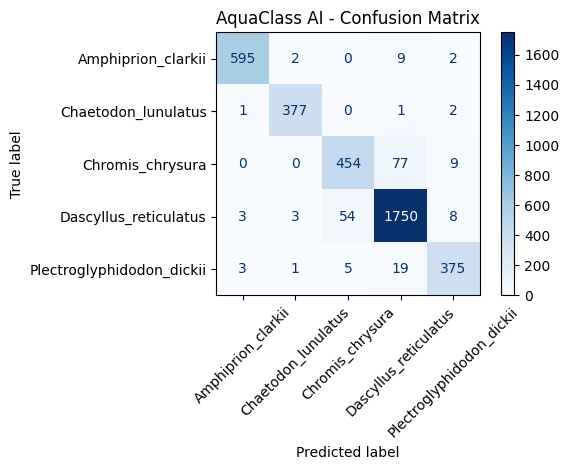

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(11, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("AquaClass AI - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/AquaClass_AI/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import torch

# Best model weights save karna
torch.save(model.state_dict(), '/content/AquaClass_AI/aquaclass_mobilenetv2_best.pth')
print("Model weights successfully saved!")

Model weights successfully saved!


In [ ]:
import torch
import os
import json

print("PyTorch version:", torch.__version__)
print("Imports successful!")

PyTorch version: 2.11.0+cu130
Imports successful!


In [ ]:
print("Model exists:", "model" in globals())

print("\nModel-related variables:")
print([name for name in globals() if "model" in name.lower()])

Model exists: True

Model-related variables:
['models', 'model', 'best_model_weights']


In [ ]:
import os

print("AquaClass_AI folder exists:",
      os.path.exists("/content/AquaClass_AI"))

if os.path.exists("/content/AquaClass_AI"):
    for root, dirs, files in os.walk("/content/AquaClass_AI"):
        for file in files:
            if file.endswith((".pth", ".pt", ".onnx")):
                print(os.path.join(root, file))

AquaClass_AI folder exists: True
/content/AquaClass_AI/aquaclass_mobilenetv2_best.pth


In [ ]:
import os

for root, dirs, files in os.walk("/content/AquaClass_AI"):
    print("\nFolder:", root)
    print("Files:", files)


Folder: /content/AquaClass_AI
Files: ['confusion_matrix.png', 'aquaclass_mobilenetv2_best.pth']

Folder: /content/AquaClass_AI/dataset
Files: []

Folder: /content/AquaClass_AI/dataset/Amphiprion_clarkii
Files: []

Folder: /content/AquaClass_AI/dataset/Amphiprion_clarkii/fish_04
Files: ['fish_004401697134_17312.png', 'fish_003773986016_21249.png', 'fish_004402217134_21200.png', 'fish_003421525277_20029.png', 'fish_004237056932_20197.png', 'fish_000001099599_07827.png', 'fish_003554635480_10732.png', 'fish_000011529599_08314.png', 'fish_000005849599_08080.png', 'fish_003585205556_09357.png', 'fish_003754245970_27031.png', 'fish_000155219598_07535.png', 'fish_004341257063_21174.png', 'fish_000019199598_05613.png', 'fish_000044239598_05964.png', 'fish_004283686992_16268.png', 'fish_000031070001_03043.png', 'fish_000008919599_08200.png', 'fish_000014549599_08463.png', 'fish_000060489598_06115.png', 'fish_003421845277_19913.png', 'fish_004204616876_11853.png', 'fish_004182896838_21856.png',

In [ ]:
import os
import torch
from google.colab import files

# 1. Ensure directory exists
os.makedirs('/content/AquaClass_AI', exist_ok=True)

# 2. Check if model variable exists and save it
if 'model' in globals():
    torch.save(model.state_dict(), '/content/AquaClass_AI/aquaclass_mobilenetv2_best.pth')
    print("Model weights successfully saved!")
else:
    print("Model variable memory mein nahi hai. Koi baat nahi, neeche search kar rahe hain...")

# 3. Search for any .pth file in Colab
found_files = []
for root, dirs, files_list in os.walk('/content'):
    for file in files_list:
        if file.endswith('.pth'):
            full_path = os.path.join(root, file)
            found_files.append(full_path)
            print(f"Mil gayi file yahan: {full_path}")

# 4. Automatically download the first found .pth file
if found_files:
    files.download(found_files[0])
else:
    print("Koi .pth file nahi mili. Aap apna training wala cell dobara run kar ke phir se save kar lein.")


Model weights successfully saved!
Mil gayi file yahan: /content/AquaClass_AI/aquaclass_mobilenetv2_best.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

# Search for your weights file across directories
file_name = 'aquaclass_mobilenetv2_best'
found_path = None

for root, dirs, files in os.walk('.'):
    if file_name in files:
        found_path = os.path.join(root, file_name)
        break

if found_path:
    print(f"Found your file at: {found_path}")
else:
    print(f"File '{file_name}' not found in the current directory or its subdirectories. Let's check /content/ if you are on Colab.")
    # Check standard Colab root just in case
    if os.path.exists(f"/content/{file_name}"):
        print(f"Found it at: /content/{file_name}")

File 'aquaclass_mobilenetv2_best' not found in the current directory or its subdirectories. Let's check /content/ if you are on Colab.


In [ ]:
from google.colab import files
files.download('/content/AquaClass_AI/aquaclass_mobilenetv2_best.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

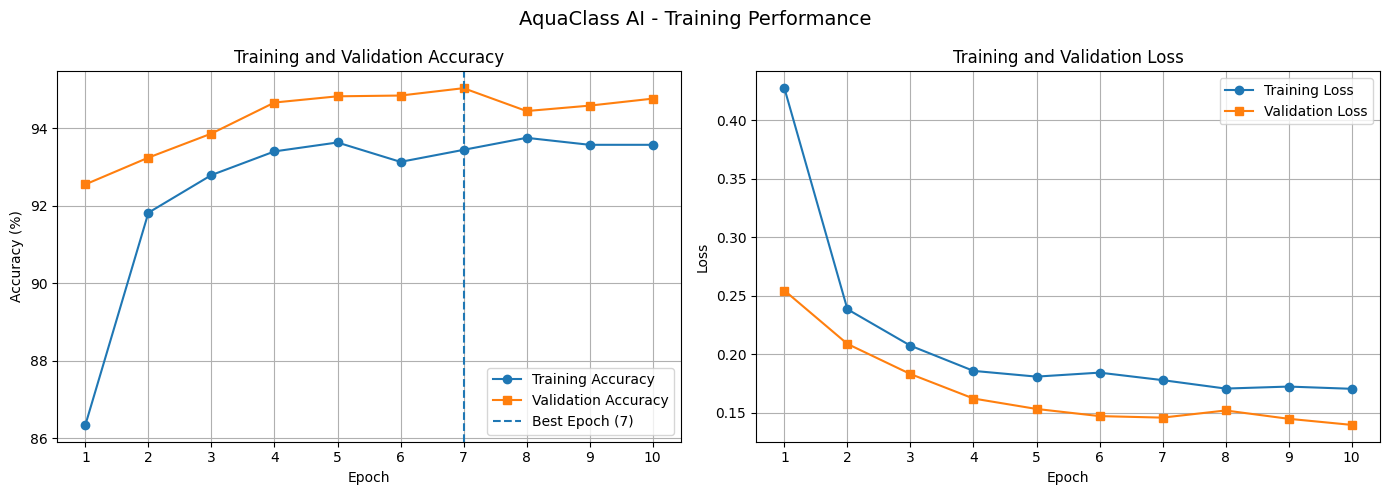

In [ ]:

import matplotlib.pyplot as plt

# Training results
epochs = range(1, 11)

train_accuracy = [86.35, 91.82, 92.79, 93.40, 93.63,
                  93.13, 93.44, 93.75, 93.57, 93.57]

val_accuracy = [92.55, 93.24, 93.86, 94.66, 94.82,
                94.84, 95.03, 94.44, 94.58, 94.76]

train_loss = [0.4272, 0.2385, 0.2074, 0.1859, 0.1810,
              0.1844, 0.1780, 0.1708, 0.1725, 0.1706]

val_loss = [0.2545, 0.2089, 0.1832, 0.1623, 0.1534,
            0.1473, 0.1460, 0.1521, 0.1450, 0.1398]

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(epochs, train_accuracy, marker='o',
             label='Training Accuracy')
axes[0].plot(epochs, val_accuracy, marker='s',
             label='Validation Accuracy')

axes[0].axvline(7, linestyle='--', label='Best Epoch (7)')
axes[0].set_title('Training and Validation Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_xticks(epochs)
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(epochs, train_loss, marker='o',
             label='Training Loss')
axes[1].plot(epochs, val_loss, marker='s',
             label='Validation Loss')

axes[1].set_title('Training and Validation Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(True)

plt.suptitle('AquaClass AI - Training Performance', fontsize=14)
plt.tight_layout()

# Save high-quality image
plt.savefig('Figure_3_Training_Curves.png',
            dpi=300, bbox_inches='tight')

plt.show()


In [ ]:
import os

print("Content folders:")
print(os.listdir('/content'))

print("\nAquaClass folders:")
for root, dirs, files in os.walk('/content'):
    if 'split_dataset' in dirs:
        print("Found:", os.path.join(root, 'split_dataset'))
        break

Content folders:
['.config', 'sample_data']

AquaClass folders:


In [ ]:
import os

for path in [
    '/content/AquaClass_AI',
    '/content/AquaClass_AI/dataset',
    '/content/AquaClass_AI/split_dataset'
]:
    print(path, "Exists:", os.path.exists(path))
    if os.path.exists(path):
        print("Contents:", os.listdir(path)[:10])

/content/AquaClass_AI Exists: False
/content/AquaClass_AI/dataset Exists: False
/content/AquaClass_AI/split_dataset Exists: False


In [ ]:
import os
import urllib.request

DATA_DIR = "/content/AquaClass_AI"
os.makedirs(DATA_DIR, exist_ok=True)

url = "https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/"

print("Project folder created:", os.path.exists(DATA_DIR))
print("Dataset source:", url)

Project folder created: True
Dataset source: https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/


In [ ]:
import os

PROJECT_DIR = "/content/AquaClass_AI"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

os.makedirs(DATASET_DIR, exist_ok=True)

print("Project folder:", os.path.exists(PROJECT_DIR))
print("Dataset folder:", os.path.exists(DATASET_DIR))
print("Dataset path:", DATASET_DIR)
print("Existing files:", os.listdir(PROJECT_DIR))

Project folder: True
Dataset folder: True
Dataset path: /content/AquaClass_AI/dataset
Existing files: ['dataset']


In [ ]:
import os
import urllib.request

BASE_URL = "https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/"

print("Dataset source:", BASE_URL)
print("Dataset folder:", DATASET_DIR)
print("Folder ready:", os.path.exists(DATASET_DIR))

Dataset source: https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/
Dataset folder: /content/AquaClass_AI/dataset
Folder ready: True


In [ ]:
import os
import urllib.request
import tarfile

BASE_URL = "https://homepages.inf.ed.ac.uk/rbf/Fish4Knowledge/GROUNDTRUTH/RECOG/Archive/fish_image/"

species_files = {
    "Dascyllus_reticulatus": "fish_01.tar",
    "Plectroglyphidodon_dickii": "fish_02.tar",
    "Chromis_chrysura": "fish_03.tar",
    "Amphiprion_clarkii": "fish_04.tar",
    "Chaetodon_lunulatus": "fish_05.tar"
}

for species, filename in species_files.items():

    class_dir = os.path.join(DATASET_DIR, species)
    os.makedirs(class_dir, exist_ok=True)

    tar_path = os.path.join(DATASET_DIR, filename)

    print("\nDownloading:", species)

    urllib.request.urlretrieve(
        BASE_URL + filename,
        tar_path
    )

    print("Extracting:", species)

    with tarfile.open(tar_path, "r") as tar:
        tar.extractall(path=class_dir)

    print("Completed:", species)

print("\nAll five species downloaded successfully!")


Downloading: Dascyllus_reticulatus
Extracting: Dascyllus_reticulatus


/tmp/ipykernel_1189/4137824329.py:32: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=class_dir)


Completed: Dascyllus_reticulatus

Downloading: Plectroglyphidodon_dickii
Extracting: Plectroglyphidodon_dickii
Completed: Plectroglyphidodon_dickii

Downloading: Chromis_chrysura
Extracting: Chromis_chrysura
Completed: Chromis_chrysura

Downloading: Amphiprion_clarkii
Extracting: Amphiprion_clarkii
Completed: Amphiprion_clarkii

Downloading: Chaetodon_lunulatus
Extracting: Chaetodon_lunulatus
Completed: Chaetodon_lunulatus

All five species downloaded successfully!


In [ ]:
import os

for species in species_files:

    class_dir = os.path.join(DATASET_DIR, species)

    images = []

    for root, dirs, files in os.walk(class_dir):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                images.append(file)

    print(f"{species}: {len(images)} images")

print("\nDataset verification completed!")

Dascyllus_reticulatus: 12112 images
Plectroglyphidodon_dickii: 2683 images
Chromis_chrysura: 3593 images
Amphiprion_clarkii: 4049 images
Chaetodon_lunulatus: 2534 images

Dataset verification completed!


In [ ]:
from sklearn.model_selection import train_test_split
import os
import shutil

SPLIT_DIR = "/content/AquaClass_AI/split_dataset"

for species in species_files:

    source = os.path.join(DATASET_DIR, species)

    images = []

    for root, dirs, files in os.walk(source):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                images.append(os.path.join(root, file))

    train_files, temp_files = train_test_split(
        images, test_size=0.30, random_state=42
    )

    val_files, test_files = train_test_split(
        temp_files, test_size=0.50, random_state=42
    )

    for split, files in [
        ("train", train_files),
        ("val", val_files),
        ("test", test_files)
    ]:

        target = os.path.join(SPLIT_DIR, split, species)
        os.makedirs(target, exist_ok=True)

        for file in files:
            shutil.copy2(
                file,
                os.path.join(target, os.path.basename(file))
            )

    print(
        species,
        "Train:", len(train_files),
        "Val:", len(val_files),
        "Test:", len(test_files)
    )

print("\nDataset splitting completed!")

Dascyllus_reticulatus Train: 8478 Val: 1817 Test: 1817
Plectroglyphidodon_dickii Train: 1878 Val: 402 Test: 403
Chromis_chrysura Train: 2515 Val: 539 Test: 539
Amphiprion_clarkii Train: 2834 Val: 607 Test: 608
Chaetodon_lunulatus Train: 1773 Val: 380 Test: 381

Dataset splitting completed!


In [ ]:
import os

for split in ["train", "val", "test"]:

    split_path = os.path.join(SPLIT_DIR, split)

    total = 0

    for species in species_files:
        class_path = os.path.join(split_path, species)

        count = sum(
            1 for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )

        total += count

    print(f"{split.upper()} Total: {total}")

print("\nAll folders verified!")

TRAIN Total: 17478
VAL Total: 3745
TEST Total: 3748

All folders verified!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
import os

search_path = "/content/drive/MyDrive"

extensions = (".pt", ".pth", ".onnx", ".ckpt")

found = []

for root, dirs, files in os.walk(search_path):
    for file in files:
        if file.lower().endswith(extensions):
            found.append(os.path.join(root, file))

if found:
    print("Model files found:")
    for path in found:
        print(path)
else:
    print("No trained model files found in Google Drive.")

No trained model files found in Google Drive.


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".pt", ".pth", ".onnx", ".ckpt")):
            print(os.path.join(root, file))

In [ ]:
import os

path = "/content/AquaClass_AI/aquaclass_mobilenetv2_best.pth"

print(os.path.exists(path))

False


In [ ]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU Available: True
GPU: Tesla T4


In [ ]:
import os

base = "/content/AquaClass_AI"

print("Project exists:", os.path.exists(base))

if os.path.exists(base):
    for root, dirs, files in os.walk(base):
        level = root.replace(base, "").count(os.sep)

        if level <= 3:
            print("  " * level + os.path.basename(root) + "/")

Project exists: False


In [ ]:
import os

print("Content folders:")
print(os.listdir("/content"))

Content folders:
['.config', 'sample_data']


In [ ]:
import os

weights_path = "/content/AquaClass_AI/aquaclass_mobilenetv2_best.pth"

if os.path.exists(weights_path):
    print("Model weights found!")
    print("Size:", round(os.path.getsize(weights_path) / (1024 * 1024), 2), "MB")
else:
    print("Model weights not found!")


Model weights not found!
